# EUR/USD Volatility Modeling with ARIMA-GARCH

## 1. Data and log-returns

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src.data import download_fred, load_prices, log_returns

download_fred()

Saved 7265 rows to data/raw/DEXUSEU.csv


In [2]:
prices = load_prices()
returns = log_returns(prices)

print(f"Period: {prices.index.min().date()} -> {prices.index.max().date()}")
print(f"Number of prices: {len(prices)} | Number of returns: {len(returns)}")
print(f"Price range: {prices.min():.4f} -> {prices.max():.4f}")
print(returns.describe().round(4))

# Sanity checks
assert prices.index.is_monotonic_increasing
assert prices.notna().all() and (prices > 0).all()
assert len(returns) == len(prices) - 1

# Log-returns add up: their sum equals the log-return over the full period
print(f"Sum of daily log-returns: {returns.sum():.4f}")
print(f"Full-period log-return:  {100 * np.log(prices.iloc[-1] / prices.iloc[0]):.4f}")

# Daily and yearly volatility
sigma_day = returns.std()
print(f"Daily vol: {sigma_day:.3f}% | Yearly vol: {np.sqrt(252) * sigma_day:.2f}%")

Period: 2011-01-03 -> 2025-12-31
Number of prices: 3751 | Number of returns: 3750
Price range: 0.9616 -> 1.4875
count    3750.0000
mean       -0.0035
std         0.5109
min        -2.6724
25%        -0.2760
50%         0.0000
75%         0.2729
max         3.0643
Name: log_return, dtype: float64
Sum of daily log-returns: -13.0427
Full-period log-return:  -13.0427
Daily vol: 0.511% | Yearly vol: 8.11%


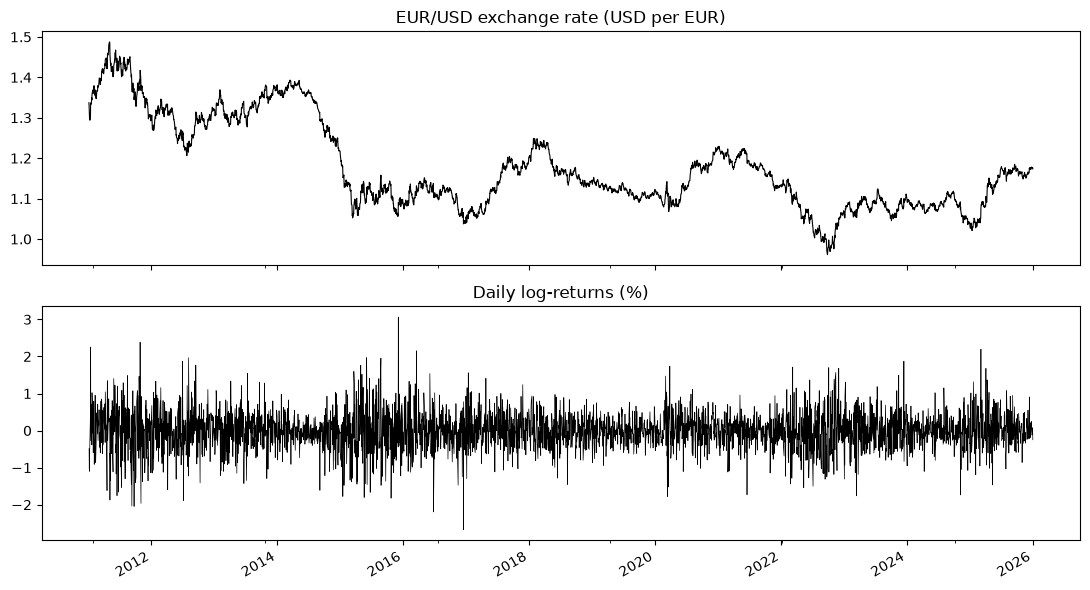

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

prices.plot(ax=axes[0], color="black", lw=0.8)
axes[0].set_title("EUR/USD exchange rate (USD per EUR)")
axes[0].set_xlabel("")

returns.plot(ax=axes[1], color="black", lw=0.5)
axes[1].set_title("Daily log-returns (%)")
axes[1].set_xlabel("")

plt.tight_layout()
fig.savefig("figures/01_prices_returns.png", dpi=150)
plt.show()